here we are going to ask 2 things and only will be execeuted 

Part 2: Why 5 * 2 Gets Ignored 

(The tools -> END Graph)When you send a two-part prompt like:"What is the recent AI news and then please multiply 5 by 2"
Watch what happens when you connect tools -> END (no loop back to the LLM):

START $\rightarrow$ tool_calling_llm: Gemini reads the prompt, sees it needs recent AI news, and emits a tool call for tavily_search (waiting to finish the web search before doing the multiplication).

tools_condition (if/else edge): Checks if the LLM asked for a tool. Since it did, it routes to the tools node (ToolNode).tools node runs Tavily: It fetches the AI news and appends a ToolMessage to State.

tools $\rightarrow$ END: Because there is a direct edge from tools to END, the graph immediately stops right after Tavily finishes! It never goes back to the LLM to summarize the news or call multiply(5, 2), so 5 * 2 is completely ignored.(Later, right around 3:58+,

 Krish replaces add_edge("tools", END) with add_edge("tools", "tool_calling_llm")—creating a ReAct loop so the LLM sees the Tavily result and then calls multiply(5, 2)!)

In [1]:
from typing import Annotated
from typing_extensions import TypedDict
from dotenv import load_dotenv

from langchain.chat_models import init_chat_model
from langchain_tavily import TavilySearch
from langchain_core.tools import tool

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

load_dotenv(override=True)

True

In [2]:
# Tool 1: Tavily Web Search
tavily_tool = TavilySearch(max_results=2)

# Tool 2: Custom Python Math Tool (docstring is required so the LLM knows what it does!)
@tool
def multiply(a: int, b: int) -> int:
    """Multiply a and b.

    Args:
        a: first int
        b: second int
    """
    return a * b

tools = [tavily_tool, multiply]

In [3]:
llm = init_chat_model("google_genai:gemini-3.5-flash-lite")
llm_with_tools = llm.bind_tools(tools)

In [4]:
class State(TypedDict):
    messages: Annotated[list, add_messages]

# Node definition
def tool_calling_llm(state: State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

# Build Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

# Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message from LLM is a tool call -> routes to "tools"
    # If the latest message is NOT a tool call -> routes to END
    tools_condition,
)
builder.add_edge("tools", END)  # <--- Stops right after the first tool runs!

graph = builder.compile()

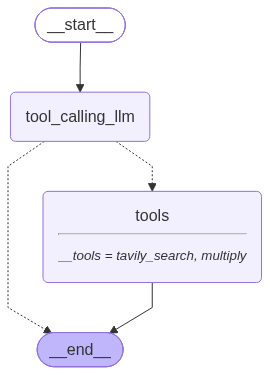

In [5]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    print(graph.get_graph().draw_ascii())

In [6]:
response = graph.invoke(
    {"messages": "What is the recent ai news and then please multiply 5 by 2"}
)

for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is the recent ai news and then please multiply 5 by 2
================================== Ai Message ==================================

[]
Tool Calls:
  tavily_search (call_11285283629954864857)
 Call ID: call_11285283629954864857
  Args:
    time_range: week
    query: latest AI news
    search_depth: basic
  multiply (call_11285283629954864020)
 Call ID: call_11285283629954864020
  Args:
    b: 2
    a: 5
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://aiweekly.co/ai-news-today", "title": "AI News Today, November 24: Top Stories | AI Weekly", "content": "CrowdStrike seals $43.9B all-stock buy of Zscaler\n\nMarlowe nabs $277M seed to run AI on non-Nvidia chips\n\nApple rolls out Siri AI and opens third-party developer preview\n\nOpe